# MIS373 - AI For Business

## Sale Performance Prediction

**Prepared by:** Thi Thao Linh Le

## Table of Content

1. [Executive Summary](#cell_Summary)

2. [Data Preprocessing](#cell_Preprocessing)

3. [AI Model Development](#cell_model)

4. [Experiments Report](#cell_report)



<a id = "cell_Summary"></a>
## 1. Executive Summary

RetailPro, a retail company specializing in consumer electronics, home appliances, and personal gadgets, seeks to improve its sales forecasting capabilities to better inform business strategies and operational decisions. The objective of this analysis was to develop predictive models to accurately estimate sales performance using a dataset of 2,000 records across 21 sales-related features, including customer foot traffic, promotional frequency, and product variety.

The data was preprocessed to handle missing values, normalize features and change all the features to binary variables for model readability. Multiple models were then developed and evaluated, including linear regression, ridge regression and multi-layer perceptron (MLP) models. Upon reviewing their error rates (MSE, RMSE, MAE, and MAPE) and correlation coefficients
(Table 8 & 9), MLR Model 4 with alpha=1 is proved to have the best performance; however, to capture all potentially impacted features across the data set, MLP model is prioritized for business adoption. Model 3, a multi-layer perceptron (MLP) model with two layers and ReLU activation, achieved the best performance with the lowest RMSE of 1,195.49, MAE of 950.99, and a correlation of 0.96, indicating strong predictive accuracy and robustness.

Despite its strong performance, several limitations were identified, such as the dataset's relatively small size, lack of external market data, and potential overfitting risk due to model complexity. Recommendations include expanding the dataset, incorporating external economic indicators, and refining model architecture to enhance generalization and applicability in real-world retail scenarios.

<a id = "cell_Preprocessing"></a>
## 2. Data Preprocessing

In [ ]:
#Loading Python Libraries
from __future__ import print_function
import os
import math
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [ ]:
#Read the sales performance csv file
sales_data_org = pd.read_csv("/content/Part1_sales_performance_data.csv")
print('Table 1: First 10 records of dataset')
display(sales_data_org.head(10))
print('Number of records read: ', sales_data_org.size)

Table 1: First 10 records of dataset


,Store Size (sq ft),Number of Employees,Advertising Spend ($),Product Variety,Seasonality Index,Customer Foot Traffic,Price Index,Competitor Pricing,Customer Satisfaction Score,Promotional Frequency,Online Sales (%),Product Return Rate (%),Supply Chain Efficiency Index,Economic Index,Market Share (%),Customer Demographics (Age Group),Store Location Type,Weather Impact Index,Store Opening Hours,Advertising Medium Mix (%),Sales ($)
0,8270,34,63912,233,3,13878,152,136,7.177197,7,40,21.072239,84,61.440579,24.385816,25-34,Rural,1.772686,77,30,31239.32047
1,1860,102,61272,1064,4,16120,234,243,7.202245,5,11,17.762790,79,99.898315,6.038915,25-34,Rural,10.739561,75,30,34985.56131
2,6390,26,43051,1148,2,2986,232,233,6.535659,5,40,6.296197,76,71.554261,4.180262,45-54,Urban,6.550752,77,35,31166.97326
3,6191,47,79854,1313,1,11825,123,122,6.003944,3,56,11.843460,95,96.584300,15.962231,45-54,Urban,12.167926,97,40,31759.42749
4,6734,70,83736,1264,2,10193,127,122,8.559455,9,52,24.786324,85,71.539903,17.202212,18-24,Urban,10.108129,84,45,31880.39810
5,7265,77,66618,757,4,18430,161,147,8.145006,10,31,8.930206,78,96.406989,3.616998,35-44,Urban,20.663328,93,62,32659.11049
6,1466,24,2920,1438,1,3176,116,102,8.071616,5,19,16.734582,96,66.784272,9.250050,25-34,Rural,6.176189,63,53,22164.60940
7,5426,24,78219,1442,4,19722,119,100,7.639515,6,39,21.858813,62,88.027149,8.620157,35-44,Suburban,5.032526,64,61,32439.82216
8,6578,113,77872,1215,2,11047,102,95,8.102909,3,42,16.731171,87,97.550101,6.400427,45-54,Rural,23.952157,73,39,30843.30032
9,9322,115,82132,278,3,17884,242,252,8.807065,10,28,12.445405,81,82.299034,10.153506,35-44,Urban,23.737915,60,54,38050.27859


Number of records read:  42000


In [ ]:
# Finding column types
sales_data_org.dtypes

,0
Store Size (sq ft),int64
Number of Employees,int64
Advertising Spend ($),int64
Product Variety,int64
Seasonality Index,int64
Customer Foot Traffic,int64
Price Index,int64
Competitor Pricing,int64
Customer Satisfaction Score,float64
Promotional Frequency,int64


In [ ]:
#Print table of general statistics for each variable in dataset
print('Table 2: Statistical overview of dataset variables')
sales_data_org.describe(include='all')

Table 2: Statistical overview of dataset variables


,Store Size (sq ft),Number of Employees,Advertising Spend ($),Product Variety,Seasonality Index,Customer Foot Traffic,Price Index,Competitor Pricing,Customer Satisfaction Score,Promotional Frequency,Online Sales (%),Product Return Rate (%),Supply Chain Efficiency Index,Economic Index,Market Share (%),Customer Demographics (Age Group),Store Location Type,Weather Impact Index,Store Opening Hours,Advertising Medium Mix (%),Sales ($)
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000,2000,2000.000000,2000.000000,2000.000000,2000.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,3,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35-44,Urban,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,520,961,NaN,NaN,NaN,NaN
mean,5562.773000,69.259000,50755.582500,807.890500,2.92500,10584.394500,172.32100,171.505000,7.501991,5.500000,35.516000,14.958329,79.260000,75.074344,15.727312,NaN,NaN,12.691474,79.930000,49.562000,30385.426733
std,2583.696539,28.716219,28972.976803,404.661208,1.41682,5542.201719,42.78873,44.040002,0.855592,2.875436,14.691176,5.794366,11.441803,14.451908,8.437693,NaN,NaN,7.171267,11.947069,11.665256,3504.377831
min,1001.000000,20.000000,1136.000000,100.000000,1.00000,1011.000000,100.00000,82.000000,6.000356,1.000000,10.000000,5.000186,60.000000,50.048248,1.005841,NaN,NaN,0.028809,60.000000,30.000000,21509.646240
25%,3358.250000,44.000000,26052.500000,461.750000,2.00000,5756.750000,135.75000,134.000000,6.760902,3.000000,23.000000,9.893783,69.000000,62.645669,8.480785,NaN,NaN,6.640101,69.000000,39.000000,27788.927205
50%,5643.000000,69.000000,50054.000000,796.500000,3.00000,10617.000000,171.00000,171.000000,7.522520,6.000000,36.000000,15.001392,79.000000,74.656048,15.796187,NaN,NaN,12.765055,80.000000,50.000000,30449.020020
75%,7854.750000,94.000000,76892.000000,1174.000000,4.00000,15488.000000,209.00000,208.000000,8.227827,8.000000,48.000000,19.903119,89.000000,87.869689,23.152919,NaN,NaN,18.927314,90.000000,60.000000,32898.889783


In [ ]:
# Identification of missing values
missing = sales_data_org.isnull().sum()
missing = missing[missing > 0]
missing.sort_values(ascending=False)

,0


Note: *No missing values have been identified in this dataset.*

In [ ]:
#Select numeric columns and change categorical variables into dummy coding.
sales_data_num = sales_data_org.select_dtypes(include='number')
sales_data_loctype= pd.get_dummies(sales_data_org['Store Location Type'], prefix='loctype')
sales_data_age= pd.get_dummies(sales_data_org['Customer Demographics (Age Group)'], prefix='AgeGroup')
sales_data = pd.concat([sales_data_num, sales_data_loctype, sales_data_age], axis=1, join='inner')
label_col = 'Sales ($)'
sales_data.head(10)

,Store Size (sq ft),Number of Employees,Advertising Spend ($),Product Variety,Seasonality Index,Customer Foot Traffic,Price Index,Competitor Pricing,Customer Satisfaction Score,Promotional Frequency,Online Sales (%),Product Return Rate (%),Supply Chain Efficiency Index,Economic Index,Market Share (%),Weather Impact Index,Store Opening Hours,Advertising Medium Mix (%),Sales ($),loctype_Rural,loctype_Suburban,loctype_Urban,AgeGroup_18-24,AgeGroup_25-34,AgeGroup_35-44,AgeGroup_45-54
0,8270,34,63912,233,3,13878,152,136,7.177197,7,40,21.072239,84,61.440579,24.385816,1.772686,77,30,31239.32047,True,False,False,False,True,False,False
1,1860,102,61272,1064,4,16120,234,243,7.202245,5,11,17.762790,79,99.898315,6.038915,10.739561,75,30,34985.56131,True,False,False,False,True,False,False
2,6390,26,43051,1148,2,2986,232,233,6.535659,5,40,6.296197,76,71.554261,4.180262,6.550752,77,35,31166.97326,False,False,True,False,False,False,True
3,6191,47,79854,1313,1,11825,123,122,6.003944,3,56,11.843460,95,96.584300,15.962231,12.167926,97,40,31759.42749,False,False,True,False,False,False,True
4,6734,70,83736,1264,2,10193,127,122,8.559455,9,52,24.786324,85,71.539903,17.202212,10.108129,84,45,31880.39810,False,False,True,True,False,False,False
5,7265,77,66618,757,4,18430,161,147,8.145006,10,31,8.930206,78,96.406989,3.616998,20.663328,93,62,32659.11049,False,False,True,False,False,True,False
6,1466,24,2920,1438,1,3176,116,102,8.071616,5,19,16.734582,96,66.784272,9.250050,6.176189,63,53,22164.60940,True,False,False,False,True,False,False
7,5426,24,78219,1442,4,19722,119,100,7.639515,6,39,21.858813,62,88.027149,8.620157,5.032526,64,61,32439.82216,False,True,False,False,False,True,False
8,6578,113,77872,1215,2,11047,102,95,8.102909,3,42,16.731171,87,97.550101,6.400427,23.952157,73,39,30843.30032,True,False,False,False,False,False,True
9,9322,115,82132,278,3,17884,242,252,8.807065,10,28,12.445405,81,82.299034,10.153506,23.737915,60,54,38050.27859,False,False,True,False,False,True,False


In [ ]:
#Split data for training & testing in which random_state parameter is used to make sure consistency during training and testing process.
train_size, valid_size, test_size = (0.7, 0.3, 0.0)
sales_train, sales_valid = train_test_split(sales_data,
                                      test_size=valid_size,
                                      random_state=2025)

In [ ]:
sales_y_train = sales_train[[label_col]]
sales_x_train = sales_train.drop(label_col, axis=1)
sales_y_valid = sales_valid[[label_col]]
sales_x_valid = sales_valid.drop(label_col, axis=1)

print('Size of training set: ', len(sales_x_train))
print('Size of validation set: ', len(sales_x_valid))

Size of training set:  1400
Size of validation set:  600


In [ ]:
#Use imputation model to impute both training and validation data.
print('Missing training values before imputation = ', sales_x_train.isnull().sum().sum())
print('Missing validation values before imputation = ', sales_x_valid.isnull().sum().sum())

imputer = SimpleImputer(missing_values=np.nan, strategy='mean').fit(sales_x_train)
sales_x_train = pd.DataFrame(imputer.transform(sales_x_train),
                            columns = sales_x_train.columns, index = sales_x_train.index)
sales_x_valid = pd.DataFrame(imputer.transform(sales_x_valid),
                            columns = sales_x_valid.columns, index = sales_x_valid.index)

print('Missing training values after imputation = ', sales_x_train.isnull().sum().sum())
print('Missing validation values after imputation = ', sales_x_valid.isnull().sum().sum())

Missing training values before imputation =  0
Missing validation values before imputation =  0
Missing training values after imputation =  0
Missing validation values after imputation =  0


In [ ]:
#Scale training & testing datasets to [-1,1] range
scaler = MinMaxScaler(feature_range=(0, 1), copy=True).fit(sales_x_train)
ames_x_train = pd.DataFrame(scaler.transform(sales_x_train),
                            columns = sales_x_train.columns, index = sales_x_train.index)
ames_x_valid = pd.DataFrame(scaler.transform(sales_x_valid),
                            columns = sales_x_valid.columns, index = sales_x_valid.index)

print('X train min =', round(sales_x_train.min().min(),4), '; max =', round(sales_x_train.max().max(), 4))
print('X valid min =', round(sales_x_valid.min().min(),4), '; max =', round(sales_x_valid.max().max(), 4))

X train min = 0.0 ; max = 99725.0
X valid min = 0.0 ; max = 99618.0


In [ ]:
print('Table 3: Preview of first 10 records in scaled training dataset')
sales_x_train.head(10)

Table 3: Preview of first 10 records in scaled training dataset


,Store Size (sq ft),Number of Employees,Advertising Spend ($),Product Variety,Seasonality Index,Customer Foot Traffic,Price Index,Competitor Pricing,Customer Satisfaction Score,Promotional Frequency,Online Sales (%),Product Return Rate (%),Supply Chain Efficiency Index,Economic Index,Market Share (%),Weather Impact Index,Store Opening Hours,Advertising Medium Mix (%),loctype_Rural,loctype_Suburban,loctype_Urban,AgeGroup_18-24,AgeGroup_25-34,AgeGroup_35-44,AgeGroup_45-54
976,6182.0,36.0,62576.0,534.0,3.0,9402.0,244.0,263.0,7.967173,9.0,12.0,13.847543,91.0,84.056448,11.847842,5.404122,73.0,52.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1041,7035.0,31.0,17260.0,1274.0,4.0,13634.0,129.0,125.0,7.856062,4.0,19.0,15.692253,74.0,88.128810,27.103048,5.456941,71.0,60.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1195,4223.0,44.0,6313.0,1490.0,1.0,4853.0,178.0,174.0,6.740547,10.0,49.0,18.878783,97.0,74.407974,24.260487,20.177152,100.0,42.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
303,8806.0,108.0,52759.0,1312.0,1.0,6607.0,170.0,156.0,8.335479,4.0,60.0,21.146743,99.0,50.835305,2.207291,18.357653,93.0,54.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1405,4380.0,25.0,40876.0,693.0,1.0,4466.0,113.0,114.0,6.548366,10.0,40.0,22.214394,88.0,72.298056,19.920951,21.081812,100.0,66.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
754,1125.0,68.0,24569.0,563.0,2.0,18761.0,236.0,235.0,8.723888,6.0,38.0,22.931577,64.0,69.520749,8.721357,10.602873,93.0,40.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
739,9172.0,25.0,32379.0,765.0,4.0,17344.0,199.0,180.0,6.901169,6.0,27.0,23.655961,86.0,94.765978,9.796415,3.573425,96.0,42.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
170,6249.0,40.0,62753.0,1193.0,5.0,10784.0,167.0,174.0,8.525875,2.0,45.0,10.086982,76.0,94.692934,11.592915,7.028754,66.0,35.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1433,5167.0,105.0,4748.0,277.0,1.0,14854.0,201.0,211.0,8.493036,9.0,16.0,16.094115,71.0,74.387685,2.539041,23.422586,98.0,33.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
35,4890.0,31.0,76945.0,912.0,3.0,13500.0,161.0,158.0,6.127574,10.0,57.0,12.360776,86.0,68.741685,4.173856,4.230294,60.0,50.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [ ]:
print('Table 4: Preview of first 10 records in scaled validation dataset')
sales_x_valid.head(10)

Table 4: Preview of first 10 records in scaled validation dataset


,Store Size (sq ft),Number of Employees,Advertising Spend ($),Product Variety,Seasonality Index,Customer Foot Traffic,Price Index,Competitor Pricing,Customer Satisfaction Score,Promotional Frequency,Online Sales (%),Product Return Rate (%),Supply Chain Efficiency Index,Economic Index,Market Share (%),Weather Impact Index,Store Opening Hours,Advertising Medium Mix (%),loctype_Rural,loctype_Suburban,loctype_Urban,AgeGroup_18-24,AgeGroup_25-34,AgeGroup_35-44,AgeGroup_45-54
1746,4179.0,104.0,37405.0,315.0,1.0,7021.0,200.0,188.0,7.997345,6.0,35.0,8.490208,93.0,61.019475,2.904359,12.326445,76.0,37.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
844,8546.0,33.0,92632.0,1416.0,3.0,11426.0,107.0,109.0,6.140695,8.0,48.0,8.864003,65.0,87.759275,15.840405,5.200917,84.0,32.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1520,9595.0,25.0,98999.0,495.0,1.0,18186.0,219.0,225.0,8.089327,3.0,24.0,13.914518,96.0,57.289402,25.005103,4.124365,75.0,64.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
1829,3817.0,116.0,62816.0,275.0,3.0,18883.0,135.0,123.0,8.842819,6.0,29.0,11.155081,98.0,92.795724,29.434118,0.108471,69.0,40.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
719,5432.0,95.0,52934.0,346.0,1.0,2806.0,174.0,179.0,7.721743,1.0,49.0,14.878377,96.0,72.345255,14.306703,7.797719,69.0,34.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
463,5492.0,22.0,66901.0,1072.0,4.0,10894.0,232.0,216.0,7.660676,1.0,13.0,17.834865,88.0,88.338760,17.161303,15.361861,82.0,34.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1386,2682.0,79.0,82326.0,1269.0,1.0,5077.0,201.0,193.0,8.933003,1.0,52.0,9.128177,96.0,89.796792,16.876198,12.578135,86.0,49.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
436,1412.0,88.0,74493.0,629.0,1.0,9261.0,132.0,137.0,7.612817,1.0,54.0,15.311876,99.0,65.609437,18.427762,24.669713,60.0,59.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
475,6486.0,38.0,87908.0,598.0,2.0,12384.0,213.0,215.0,8.253238,7.0,29.0,17.587251,78.0,85.440315,4.092929,22.163216,62.0,34.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1221,2771.0,96.0,93892.0,1016.0,5.0,6988.0,112.0,127.0,8.708221,9.0,28.0,21.208547,98.0,53.116275,17.863959,13.692806,96.0,50.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


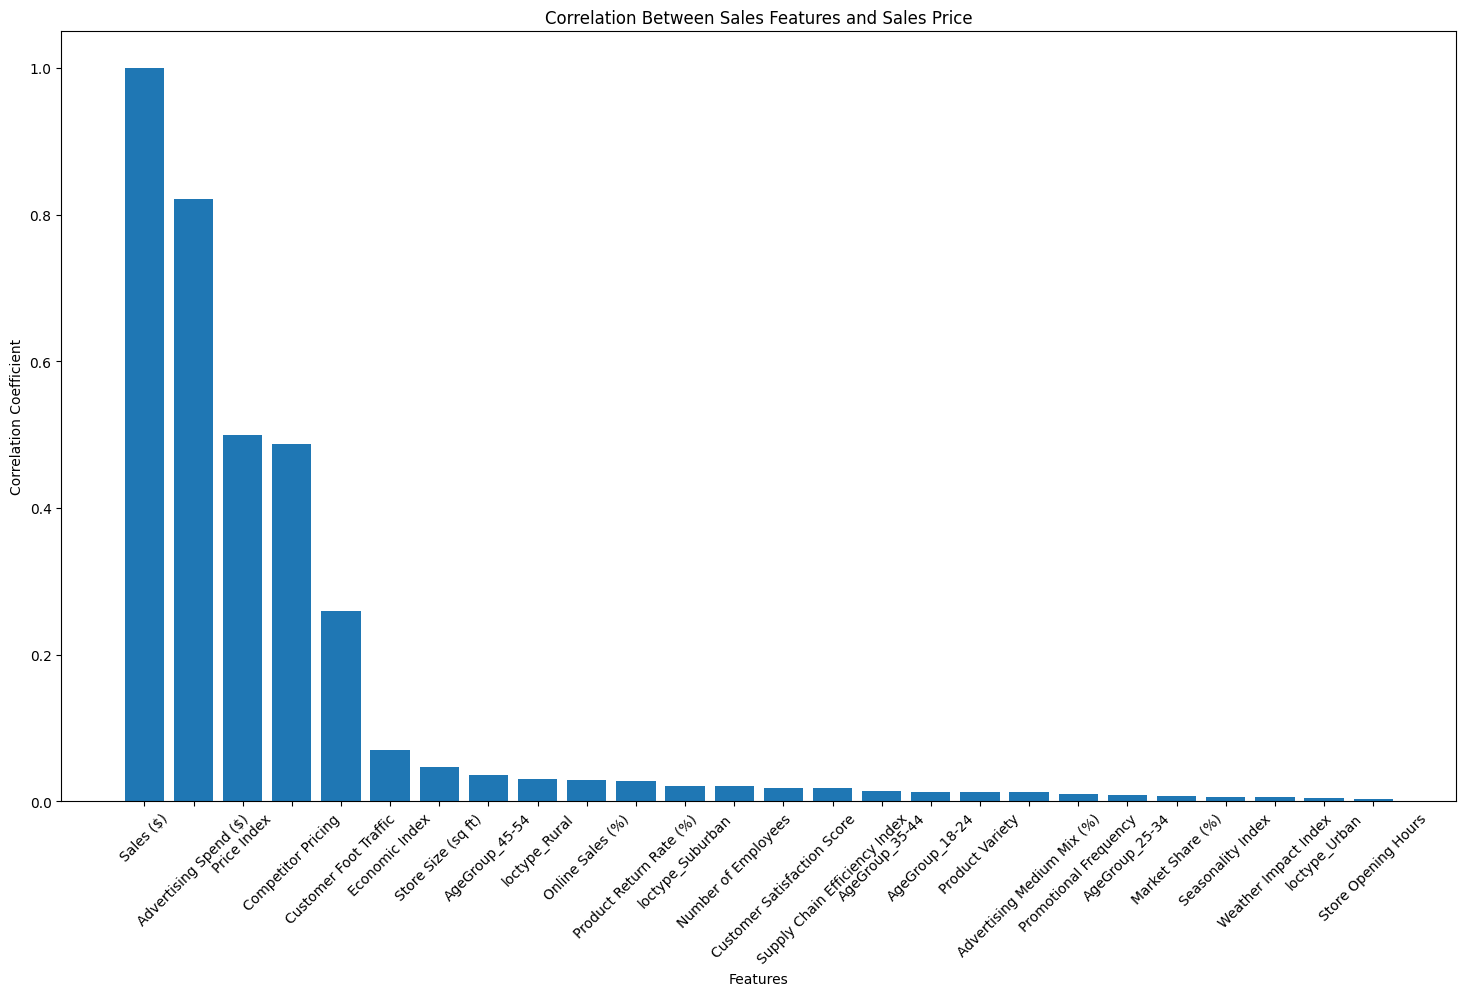

Figure 1: Correlation between sales price and each sales feature


In [ ]:
import matplotlib.pyplot as plt
correlation_matrix = sales_data.corr()
target_correlation = correlation_matrix['Sales ($)']
sorted_correlation = target_correlation.abs().sort_values(ascending=False)
top_features = sorted_correlation.index.tolist()
plt.figure(figsize=(18, 10))
plt.bar(top_features, sorted_correlation)
plt.xlabel('Features')
plt.ylabel('Correlation Coefficient')
plt.title('Correlation Between Sales Features and Sales Price')
plt.xticks(rotation=45)
plt.show()
print('Figure 1: Correlation between sales price and each sales feature')

Figure 1 illustrates strong correlation between a store's sales and advertising spend, price index, and competitor pricing, suggesting these are key drivers of sales performance. In contrast, In contrast, features such as store opening hours, weather impact index, seasonality index, location in urban, and market share (%) show very weak correlation with sales, indicating potentially minimal influence on sales outcomes.

To assist in developing relevant multi-linear regression models,
feature selection based on this correlation analysis will be employed (Table 5).

<a id = "cell_model"></a>
# **3. AI Model Development**

This experiment invloves testing 24 models including 4 multi-linear regression (MLR) and 20 multi-layer perception (MLP) models. Before testing, location type and age group attributes are changed into a series of binary variables. All data were pre-processed and normalized before training to ensure attributes on different scales could be effectively learned by the neural network as they all potentially have impact on sales performance (Massaro, 2018).

All AI models developed for this study were evaluated and compared based on their recorded performance, as shown in Table X. The following metrics were used to assess model accuracy and effectiveness:

- Mean Squared Error (MSE)

- Mean Absolute Error (MAE)

- Mean Absolute Percentage Error (MAPE)

- Root Mean Squared Error (RMSE)

- Correlation between predicted and actual sales on the validation set

RMSE and MAPE were selected as the primary metrics for determining the best-performing model in predicting sales.

As noted by Code Signal, whilst both MAE provides a straightforward average error without disproportionately penalizing large deviations, RMSE squares the errors before averaging, thus giving more weight to larger discrepancies. This makes it particularly effective in highlighting significant outliers or severe prediction errors. Given the objective of emphasizing large deviations and ensuring that substantial inaccuracies are more noticeable in the analysis, RMSE is chosen as the preferred metric for this study.

MAPE complements this by expressing errors as a percentage, allowing the performance to be evaluated relative to the actual sales amount. This is particularly helpful in a business context, where understanding the proportion of error in relation to expected values is crucial.

# **3.1. Multi-linear Regression Model**

Although one MLR model is required, many MLR models are tested to ensure the best one that can reflect the key drivers of sales performance and deliver reliable predictions. Each MLR model was altered by either the features it considered (using correlation analysis), or
the value of its alpha parameter. The following MLR models were developed:
- Model 1: standard multi-linear regression with all features
- Model 2: standard multi-linear regression with features that achieved a correlation with sales > 0.2
- Model 3: ridge multi-linear regression with all features, where alpha = 0.1
- Model 4: ridge multi-linear regression with all features, where alpha = 1

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import numpy as np

In [ ]:
#Generating Model 4
sales_model_4 = LinearRegression()

In [ ]:
sales_model_4.fit(sales_x_train, sales_y_train)

LinearRegression()

In [ ]:
# Predict sales based on the features of the validation data
sales_y_pred = sales_model_4.predict(sales_x_valid)

In [ ]:
# Downloading function for hyper-parameter tuning
from sklearn.linear_model import Ridge

# Generating Model 4 (Ridge Regression with alpha = 1)
sales_model_4 = Ridge(alpha=10)  # Using alpha = 1
sales_model_4.fit(sales_x_train, sales_y_train)  # Using sales training data

# Make predictions on validation data
sales_y_pred = sales_model_4.predict(sales_x_valid)

# Printing the performance results of Model 4
print('Model 4 Results:', '\n')
mse4 = mean_squared_error(sales_y_valid, sales_y_pred)
print("Mean Squared Error:", mse4)
mae4 = mean_absolute_error(sales_y_valid, sales_y_pred)
print("Mean Absolute Error:", mae4)
mape4 = mean_absolute_percentage_error(sales_y_valid, sales_y_pred)
print("Mean Absolute Percentage Error:", mape4)
rmse4 = np.sqrt(mse4)  # Calculate RMSE
print("Root Mean Squared Error:", rmse4)

# Calculate and print correlation
sales_y_valid_np = sales_y_valid.values
corr4 = np.corrcoef(sales_y_pred.flatten(), sales_y_valid_np.flatten())
print("Correlation:", corr4[0, 1])

# Printing the intercept & coefficient of Model 4
print('Model 4 Rule:', '\n')
print("Coefficients:", sales_model_4.coef_)
print("Intercept:", sales_model_4.intercept_)

Model 4 Results: 

Mean Squared Error: 39060.68127395146
Mean Absolute Error: 169.26087355164177
Mean Absolute Percentage Error: 0.0056590495148561215
Root Mean Squared Error: 197.6377526535643
Correlation: 0.9983946652103073
Model 4 Rule: 

Coefficients: [  0.05229303  -0.13590817   0.09977412   0.05026904  -6.24247888
   0.15052453  41.65466902  -0.07616469  -5.74981551   1.40976918
   0.15393761   1.71237597   4.45689292   4.61461955   0.19931031
  -0.08972627   1.52619751   0.30352586  -0.70172149  -5.51477873
   6.21650022  -1.29401098 -10.15994876  13.31912379  -1.86516405]
Intercept: [15426.60779938]


**3.2. Multi-layer Perception Models**


A series of 20 MLP models were put into testing and training process with variable combinations of architecture,
parameters and learning processes.

The following outlines the different variables considered for
this experiment:

***Architecture***

- Density - 50, 100 or 200
- Activation function - Sigmoid, Tanh or ReLU
- Drop-out - 0, 0.2 or 0.5 (only available following layers 1 & 2)
Layers - 2, 3 or 4


***Parameters***

- Learning rate - 0.001, 0.01 or 0.1
- Momentum - 0.5 or 0.8 (only for RMSprop optimised models)
- Decay - 0 or 0.9 (only for RMSprop optimised models)
- Epsilon - 1.00E-08, 1.00E-07 or 1.00E-06

***Learning approach***
- Epochs - 100, 250 or 500 (Early Stopping is applied for automatical stop if there is no improvement after 10 epochs)
- Batch size - 32, 64 or 128
- Optimiser - RMSprop, Adam or Adagrad


Of these variables, random selections were made and the following multi-layer perception
models were developed:

2-Layer Models

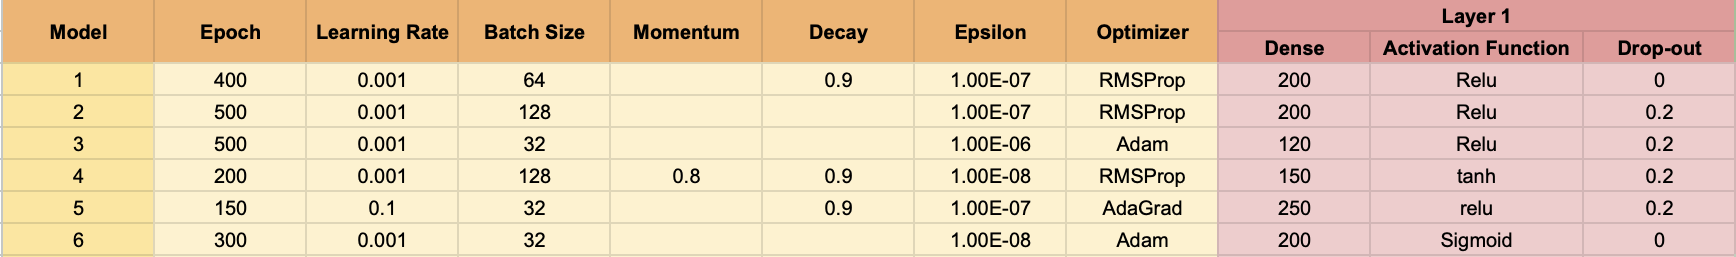

*Table 5: Architecture, parameters and learning approach for tested 2-layer MLP models*

3-Layer Models
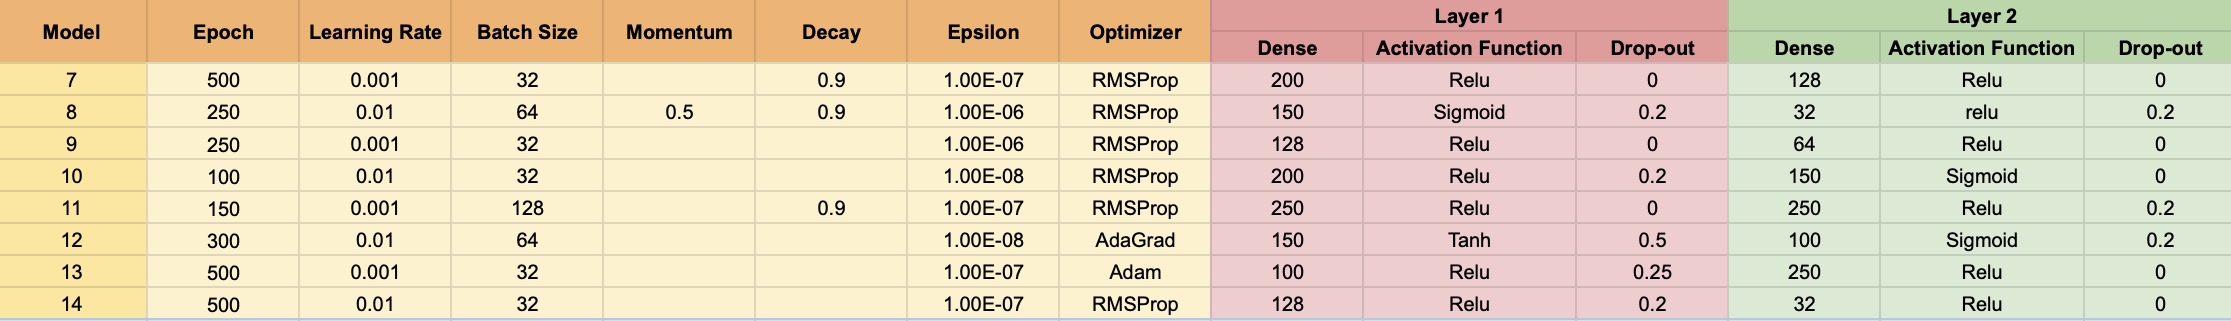
*Table 6: Architecture, parameters and learning approach for tested 3-layer MLP models*

4-Layer Models
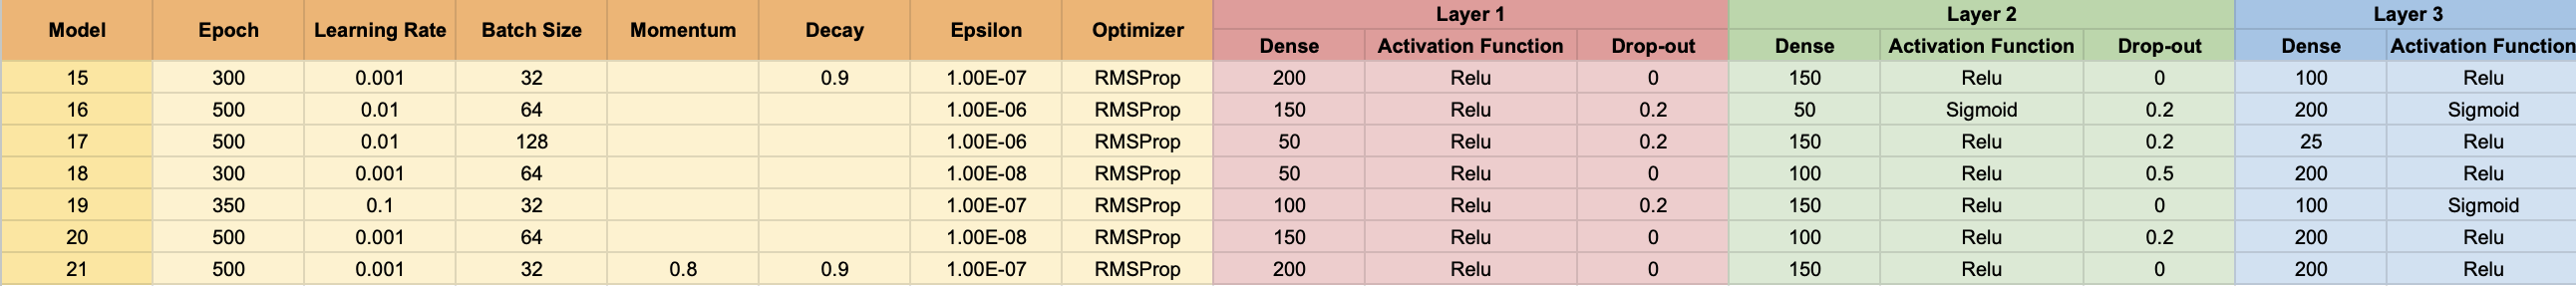
*Table 7: Architecture, parameters and learning approach for tested 4-layer MLP models*

In [ ]:
import tensorflow as tf
from tensorflow.keras import metrics
from tensorflow.keras import regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Nadam, RMSprop

In [ ]:
arr_x_train = np.array(sales_x_train)
arr_y_train = np.array(sales_y_train)
arr_x_valid = np.array(sales_x_valid)
arr_y_valid = np.array(sales_y_valid)

print('Training shape:', arr_x_train.shape)
print('Training samples: ', arr_x_train.shape[0])
print('Validation samples: ', arr_x_valid.shape[0])

Training shape: (1400, 25)
Training samples:  1400
Validation samples:  600


In [ ]:
def model_3(x_size, y_size):
    t_model = Sequential()
    t_model.add(Dense(120, input_shape=(x_size,)))  # Remove 'activation' from here
    t_model.add(Dropout(0.2))
    t_model.add(tf.keras.layers.Activation('relu'))  # Add activation as a separate layer
    t_model.add(Dense(y_size))
    t_model.compile(
        loss='mean_squared_error',
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, epsilon=1e-06, weight_decay=0.0),
        metrics=[metrics.mae])
    return(t_model)

In [ ]:
model = model_3(arr_x_train.shape[1], arr_y_train.shape[1])
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 120)            │         3,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,241 (12.66 KB)

 Trainable params: 3,241 (12.66 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.callbacks import EarlyStopping

# Set up EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',        # For regression, 'val_loss' (MSE) is typical
    patience=20,               # Stop after 10 epochs of no improvement
    restore_best_weights=True, # Restore the best weights
    verbose=1
)

In [ ]:
history = model.fit(arr_x_train, arr_y_train,
    batch_size=64,
    epochs=500,
    shuffle=True,
    verbose=2,
    validation_data=(arr_x_valid, arr_y_valid),
    callbacks=[early_stopping])

Epoch 1/500
22/22 - 0s - 14ms/step - loss: 338171968.0000 - mean_absolute_error: 16849.0996 - val_loss: 127294616.0000 - val_mean_absolute_error: 9193.9316
Epoch 2/500
22/22 - 0s - 7ms/step - loss: 137219104.0000 - mean_absolute_error: 9867.0000 - val_loss: 104908408.0000 - val_mean_absolute_error: 8729.2324
Epoch 3/500
22/22 - 0s - 7ms/step - loss: 116401160.0000 - mean_absolute_error: 9099.2080 - val_loss: 84267208.0000 - val_mean_absolute_error: 7589.3257
Epoch 4/500
22/22 - 0s - 15ms/step - loss: 96197264.0000 - mean_absolute_error: 8177.1816 - val_loss: 66433468.0000 - val_mean_absolute_error: 6717.5527
Epoch 5/500
22/22 - 0s - 7ms/step - loss: 80250472.0000 - mean_absolute_error: 7476.4858 - val_loss: 54399752.0000 - val_mean_absolute_error: 5947.8799
Epoch 6/500
22/22 - 0s - 7ms/step - loss: 71391936.0000 - mean_absolute_error: 6944.6709 - val_loss: 46338612.0000 - val_mean_absolute_error: 5475.2925
Epoch 7/500
22/22 - 0s - 13ms/step - loss: 62958324.0000 - mean_absolute_error: 

In [ ]:
train_score = model.evaluate(arr_x_train, arr_y_train, verbose=0)
valid_score = model.evaluate(arr_x_valid, arr_y_valid, verbose=0)

print('Train MAE: ', round(train_score[1], 2), ', Train Loss: ', round(train_score[0], 2))
print('Val MAE: ', round(valid_score[1], 2), ', Val Loss: ', round(valid_score[0], 2))

Train MAE:  889.8 , Train Loss:  1234544.75
Val MAE:  945.45 , Val Loss:  1402833.12


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


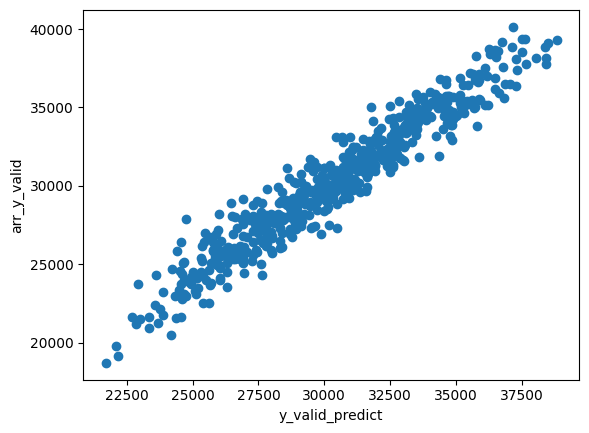

Figure 2: The Correlation between true and predicted values of Model 7
The Correlation between true and predicted values is:  0.963


In [ ]:
y_valid_predict = model.predict(arr_x_valid)
# plot
plt.scatter(arr_y_valid, y_valid_predict)
plt.ylabel('arr_y_valid')
plt.xlabel('y_valid_predict')
plt.show()

# Reshape to (number_of_samples,) instead of (1, number_of_samples)
print('Figure 2: The Correlation between true and predicted values of Model 7')
corr_result = np.corrcoef(arr_y_valid.reshape(arr_y_valid.shape[0]), y_valid_predict.reshape(y_valid_predict.shape[0]))
print('The Correlation between true and predicted values is: ',round(corr_result[0,1],3))

In [ ]:
def plot_hist(h, xsize=6, ysize=5):
    # Prepare plotting
    fig_size = plt.rcParams["figure.figsize"]
    plt.rcParams["figure.figsize"] = [xsize, ysize]

    # Get training and validation keys
    ks = list(h.keys())
    n2 = math.floor(len(ks)/2)
    train_keys = ks[0:n2]
    valid_keys = ks[n2:2*n2]

    # summarize history for different metrics
    for i in range(n2):
        plt.plot(h[train_keys[i]])
        plt.plot(h[valid_keys[i]])
        plt.title('Training vs Validation '+train_keys[i])
        plt.ylabel(train_keys[i])
        plt.xlabel('Epoch')
        plt.legend(['Train', 'Validation'], loc='upper left')
        plt.draw()
        plt.show()

    return

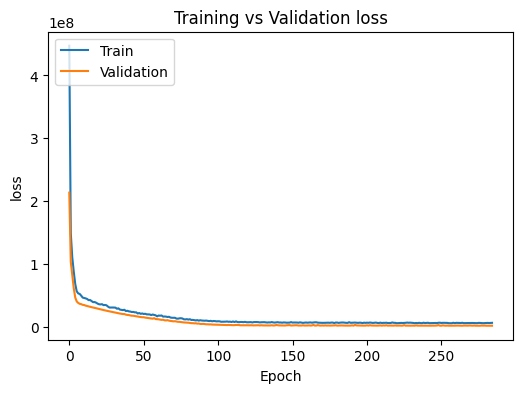

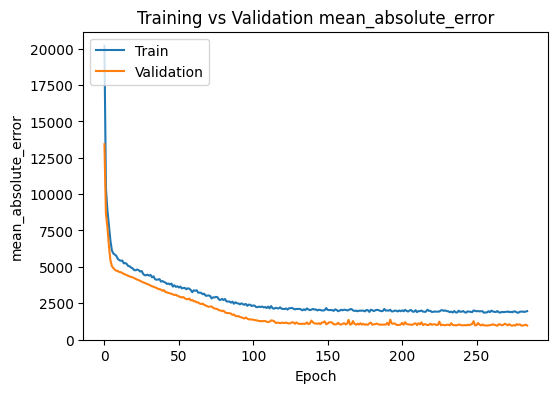

In [ ]:
hist = pd.DataFrame(history.history)

# Plot history
plot_hist(hist, xsize=6, ysize=4)

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from scipy.stats import pearsonr

# Assuming you have your true values in 'y_true' and predicted values in 'y_pred'
# These should be NumPy arrays or pandas Series
y_valid_predict = model.predict(arr_x_valid)
# Calculate MAE
mae = mean_absolute_error(arr_y_valid, y_valid_predict)

# Calculate MSE
mse = mean_squared_error(arr_y_valid, y_valid_predict)

# Calculate RMSE
rmse = np.sqrt(mse)

# Calculate Pearson correlation
correlation, _ = pearsonr(arr_y_valid.ravel(), y_valid_predict.ravel())  # Flatten arrays if needed

# Calculate MAPE
mape = mean_absolute_percentage_error(arr_y_valid, y_valid_predict)

# Print the results
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("Pearson Correlation:", correlation)
print("MAPE:", mape)


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
MAE: 950.9925397552084
MSE: 1429206.5979257473
RMSE: 1195.494290210433
Pearson Correlation: 0.9603455032286979
MAPE: 0.03224767396415759


<a id = "cell_report"></a>
# **4. Experiments Report**

Regarding Multi-linear Regression Model, the performance of the 4 models varied with RMSE ranging from 39,060 to 62,815 and MAPE from 0.57% to 0.68% (Table 8). Model 4 stands out as the best-performing model, achieving the lowest MSE (39,060.70), RMSE (197.638), and MAE (169.261), indicating its high accuracy in predicting sales outcomes with minimal error. It also has the highest correlation (0.998), reflecting a strong relationship between predicted and actual values.

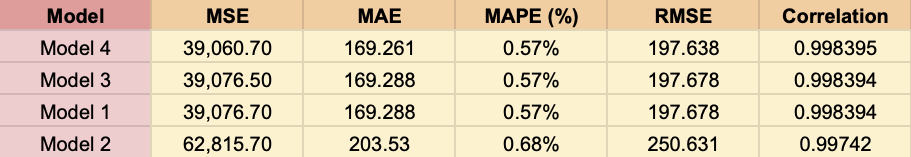

*Table 8: MLR model performance ranked by RMSE*

Regarding Multi-layer Perception Model, the performance of the 20 MLP models varied significantly, with RMSE ranging from 1,429,206 to 923,370,262 and MAPE from 3.2% to 99.6% (Table 9). Based on RMSE, MAPE, MSE, and the correlation between actual and predicted house prices, Model 3 was the the top-performing model in this analysis (Table 9).

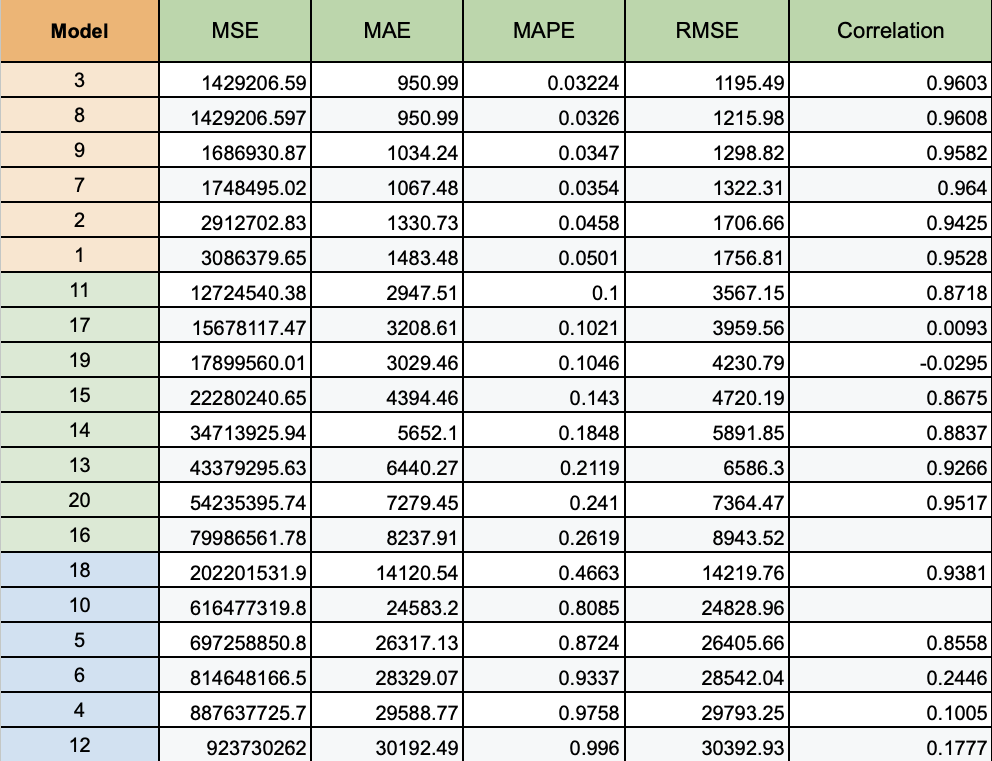
*Table 9: MLP model performance ranked by RMSE*

# 4.1. Evaluation of Multi-layer Perception Model 3

Model 3 is a multi-layer perceptron (MLP) model with the following characteristics:

**Architecture:**

Density: 120

Activation function: ReLU

Drop-out: 0.2

Layers: 2

**Parameters:**

Learning rate: 0.001

Epsilon: 1.00E-06

**Learning Approach:**

Epochs: 500

Batch size: 32

Optimizer: Adam

Across this dataset, which has sales ranging from 21,509 to 40,035 (Table 2), this model achieves an average error of 950.99 (Table 9) while The RMSE of this model is 1195.49 (Table 9), indicating that the model's predictions deviate by approximately 1,195 dollars on average from the true sales values across the validation dataset. Overall, this model is expected to estimate sales that are approximately 950 to 1,195 dollars higher or lower than RetailPro’s actual sales.

Model 3 demonstrated strong predictive performance in this sales prediction task, achieving a Mean Squared Error (MSE) of 1,429,206.59 and a Root Mean Squared Error (RMSE) of 1195.49, indicating moderate predictive accuracy on the validation set. The model also recorded a Mean Absolute Error (MAE) of 950.99, suggesting consistent prediction stability with reasonable error dispersion. Its Correlation Coefficient of 0.9603 underscores its capability to capture a substantial proportion of the variance in sales data, maintaining a relatively strong relationship between predicted and actual outcomes.

Model 3’s architecture comprises two hidden layers with ReLU activation, providing sufficient depth to uncover complex feature interactions while minimizing the risk of vanishing gradients. The model leverages the Adam optimizer, known for its adaptive learning rate and effective handling of noisy data, supporting learning stability across epochs. The selected learning rate of 0.001 balances convergence speed and training stability, promoting gradual weight updates to avoid overshooting.


In comparison to the Linear Regression Model (Model 4), which achieved a lower RMSE (197.64) and a higher correlation (0.9984) (Table 8), Model 3 exhibits higher error rates, suggesting that its neural network structure may have introduced unnecessary complexity without effectively capturing the dataset’s linear relationships. However, Model 3’s architecture provides greater flexibility in capturing potential non-linear interactions, making it more suitable for datasets with underlying complexities that a linear model might overlook.

# 4.2. Adotption of Model 3

Model 3 could be effectively employed by RetailPro to estimate sales performance across various stores, enabling management to anticipate sales fluctuations and identify potential areas for targeted marketing strategies. Alternatively, it could serve as a cross-referencing tool, allowing sales agents to validate their own projections against the model’s predictions, ensuring consistency and data-driven accuracy in sales forecasting.

To effectively implement Model 3, RetailPro would need to maintain comprehensive data collection for all input features in the model, including customer foot traffic, promotional frequency, product variety, and advertising spend. Accurate and up-to-date data across these features would enhance the model’s predictive accuracy and ensure reliable forecasting outcomes.

While Model 3 attempts to predict exact sales values, RetailPro typically uses broader sales ranges or percentage changes to guide business decisions. Consequently, the company could utilize Model 3 to gain a general understanding of expected sales trends, focusing on identifying anomalies or significant deviations from historical patterns rather than pinpointing exact sales figures.



# 4.3. Limitations and Recommendations

Model 3, a multi-layer perceptron (MLP) model, can be effectively utilized by RetailPro to forecast sales performance, aiding in inventory management, promotional strategies, and overall sales planning. The model’s architecture, consisting of two hidden layers with ReLU activation and a dropout rate of 0.2, enables it to capture complex patterns in sales data while mitigating overfitting. Its adaptive learning approach using the Adam optimizer further stabilizes training, especially given the small dataset size.

**Data Granularity and Coverage:**

Despite its promising performance, a notable limitation is the dataset size. With only 2,000 records and 21 input features, the data volume may be insufficient to fully leverage the potential of neural network architectures, which typically require more extensive datasets to prevent overfitting and achieve robust generalization (Sharma, 2021; Brownlee, 2020). Thus, while Model 3 shows adequate predictive capability on the current dataset, its scalability and reliability would need further validation with larger datasets in future iterations.

To enhance reliability, expanding the dataset with more historical sales records across different stores, timeframes, and product categories is crucial. Additionally, incorporating external data, such as economic indicators and competitor pricing, could provide a more comprehensive training set and prevent overfitting.

**Feature Relevance and Missing Influences:**

While the model incorporates sales-related features such as customer foot traffic, promotional frequency, and product variety, it lacks external market factors that can significantly impact sales predictions. For instance, external disruptions like supply chain delays or seasonal demand fluctuations are not accounted for in the current model.

RetailPro should consider augmenting the model with external data such as weather patterns, economic indices, and regional consumer spending trends to capture broader market influences, thus improving predictive accuracy.

**Model Complexity vs. Dataset Size:**

The MLP model architecture includes two hidden layers with 120 nodes, which may introduce unnecessary complexity given the relatively small dataset. Overfitting is a potential risk, as the model may learn noise rather than actual sales patterns.

To mitigate this risk, the number of nodes or layers could be implemented to ensure the model remains generalizable without excessive parameter tuning.

**Operational Scalability:**

Although Model 3 provides high predictive accuracy, its computational complexity may limit real-time implementation, particularly if data volume increases or additional features are incorporated.

RetailPro should evaluate cloud-based deployment options, such as Google Cloud or AWS, to maintain scalability and processing efficiency while managing large datasets and complex model architectures.



# Reference:

Massaro, A., Vitti, V., & Galiano, A. (2018). Model of multiple artificial neural networks oriented on sales prediction and product shelf design. International Journal on Soft Computing, Artificial Intelligence and Applications (IJSCAI), 7(3), 1-17. https://doi.org/10.5121/ijscai.2018.7301

CodeSignal. (2020). Evaluating model accuracy: MSE, RMSE, and MAE in regression analysis. In Regression models for prediction. Retrieved from https://codesignal.com/learn/courses/regression-models-for-prediction/lessons/evaluating-model-accuracy-mse-rmse-and-mae-in-regression-analysis

Brownlee, J. (2020). How much data is enough for machine learning? Machine Learning Mastery. Retrieved from https://machinelearningmastery.com/how-much-training-data/

Sharma, A. (2021). How much training data do you need for deep learning? Graphite Note. Retrieved from https://graphite-note.com/how-much-data-is-needed-for-machine-learning/